# Custom CNN training
This notebook is the executable end-to-end training/evaluation module. It uses only the training split for augmentation and class weights; validation drives callbacks; test is evaluated once after model selection.


Dataset image count: 4172
Classes: 15
Split counts:
 split
train         2920
validation     626
test           626
Name: count, dtype: int64
Preprocessing: RGB, resize to 224x224, divide pixel values by 255
Augmentation layers: ['random_flip', 'random_rotation', 'random_zoom', 'random_brightness']
Brightness value range: [0.0, 1.0]
Training class weights:


,class_name,class_index,weight
0,Pepper__bell___Bacterial_spot,0,1.052252
1,Pepper__bell___healthy,1,5.122807
2,Potato___Early_blight,2,0.988156
3,Potato___Late_blight,3,0.831909
4,Potato___healthy,4,1.819315
5,Tomato_Bacterial_spot,5,0.944984
6,Tomato_Early_blight,6,0.763399
7,Tomato_Late_blight,7,0.828369
8,Tomato_Leaf_Mold,8,1.035461
9,Tomato_Septoria_leaf_spot,9,0.814505


Custom CNN model summary:


Model: "custom_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 28, 28, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 28, 28, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 15)             │         1,935 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

...

 Non-trainable params: 960 (3.75 KB)

Training configuration: Adam, learning rate 0.001 batch size 16 maximum epochs 30 sparse categorical crossentropy, early stopping, best-validation checkpoint, and ReduceLROnPlateau
Actual training history:


,epoch,accuracy,loss,val_accuracy,val_loss,learning_rate,epoch_duration_seconds
0,1,0.140411,2.949377,0.063898,3.673947,1.000000e-03,848.636979
1,2,0.107534,2.769373,0.083067,3.555625,1.000000e-03,883.544776
2,3,0.119863,2.640656,0.118211,3.191496,1.000000e-03,827.791564
3,4,0.117466,2.568168,0.068690,3.417081,1.000000e-03,872.217479
4,5,0.116438,2.493168,0.083067,5.963129,1.000000e-04,1019.008263
5,6,0.050342,3.088885,0.089457,3.098399,1.000000e-04,670.939009
6,7,0.069863,2.787696,0.065495,2.695047,1.000000e-04,861.281307
7,8,0.065753,2.724778,0.108626,2.699359,1.000000e-04,1304.924235
8,9,0.092466,2.672781,0.103834,2.700168,1.000000e-05,709.269284
9,10,0.101027,2.735263,0.111821,2.593833,1.000000e-05,2091.112109


Actual training analysis:


{'convergence': 'Validation loss reached its observed minimum at epoch 16 (2.5719); change from first-epoch validation loss was 1.1020.',
 'overfitting': 'At the final epoch, validation loss minus training loss was -0.0658; training accuracy minus validation accuracy was -0.0051. These endpoint gaps are descriptive, not a standalone diagnosis.',
 'underfitting': 'Final training loss was 2.6379 and training accuracy was 0.1291; interpret these together with the recorded curves.',
 'validation_behavior': 'Validation loss ranged from 2.5719 to 5.9631; validation accuracy ranged from 0.0639 to 0.1406.'}

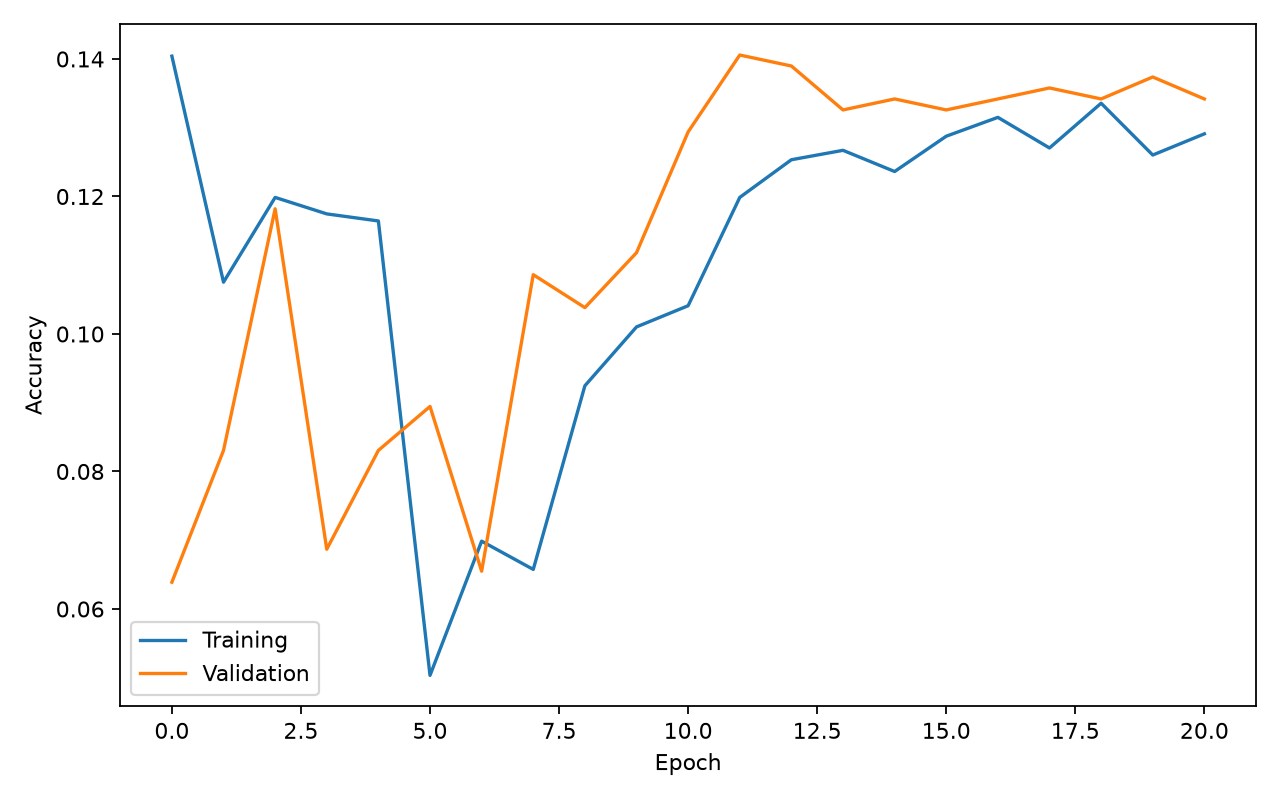

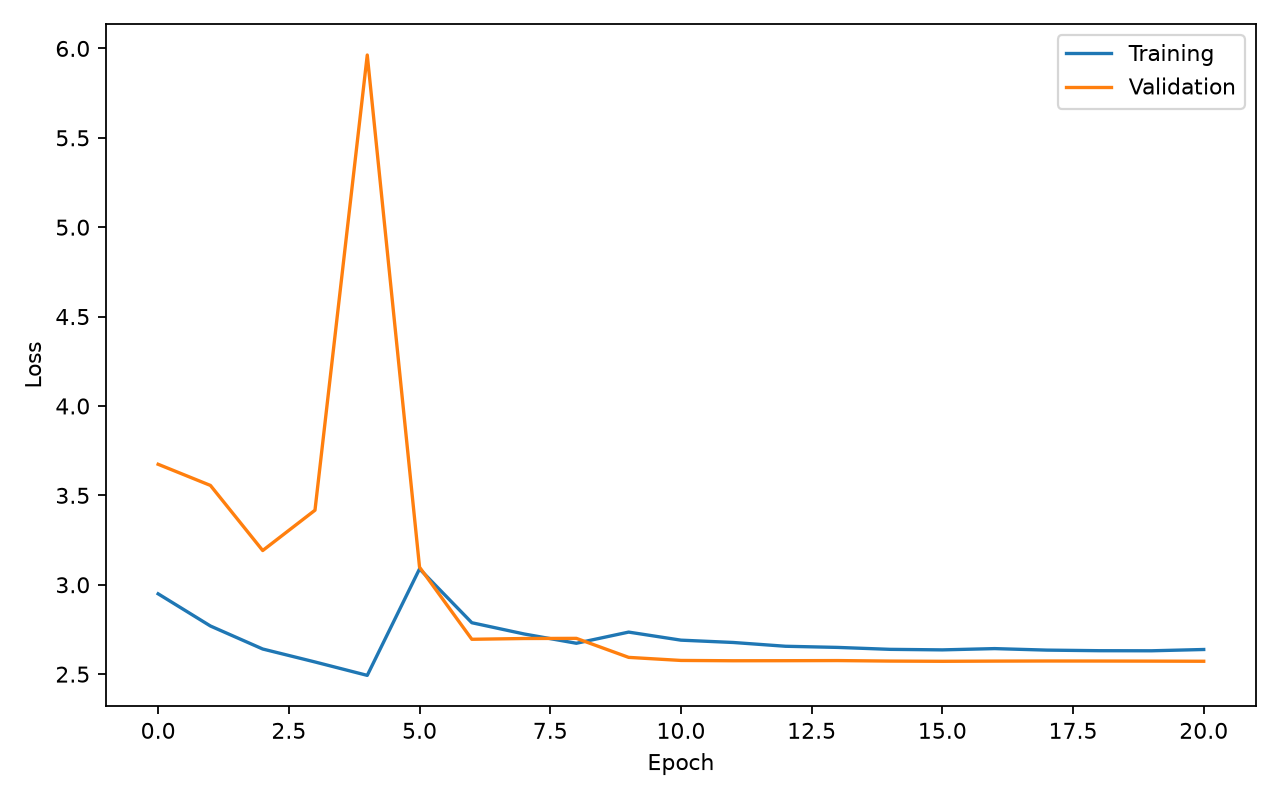

classification_report.csv


,Class,Precision,Recall,F1-score,Support
0,Pepper__bell___Bacterial_spot,0.500000,0.025000,0.047619,40
1,Pepper__bell___healthy,0.000000,0.000000,0.000000,8
2,Potato___Early_blight,0.500000,0.023256,0.044444,43
3,Potato___Late_blight,0.000000,0.000000,0.000000,50
4,Potato___healthy,0.000000,0.000000,0.000000,22
5,Tomato_Bacterial_spot,0.250000,0.090909,0.133333,44
6,Tomato_Early_blight,0.120000,0.111111,0.115385,54
7,Tomato_Late_blight,0.207207,0.450980,0.283951,51
8,Tomato_Leaf_Mold,0.133333,0.050000,0.072727,40
9,Tomato_Septoria_leaf_spot,0.089888,0.313725,0.139738,51


final_metrics.csv


,Model,Test Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted Precision,Weighted Recall,Weighted F1
0,Custom CNN,0.134185,0.129296,0.115926,0.071179,0.137156,0.134185,0.081522


model_complexity.csv


,total_parameters,trainable_parameters,non_trainable_parameters,training_time_seconds,epochs_completed
0,425167,424207,960,46568.640399,21


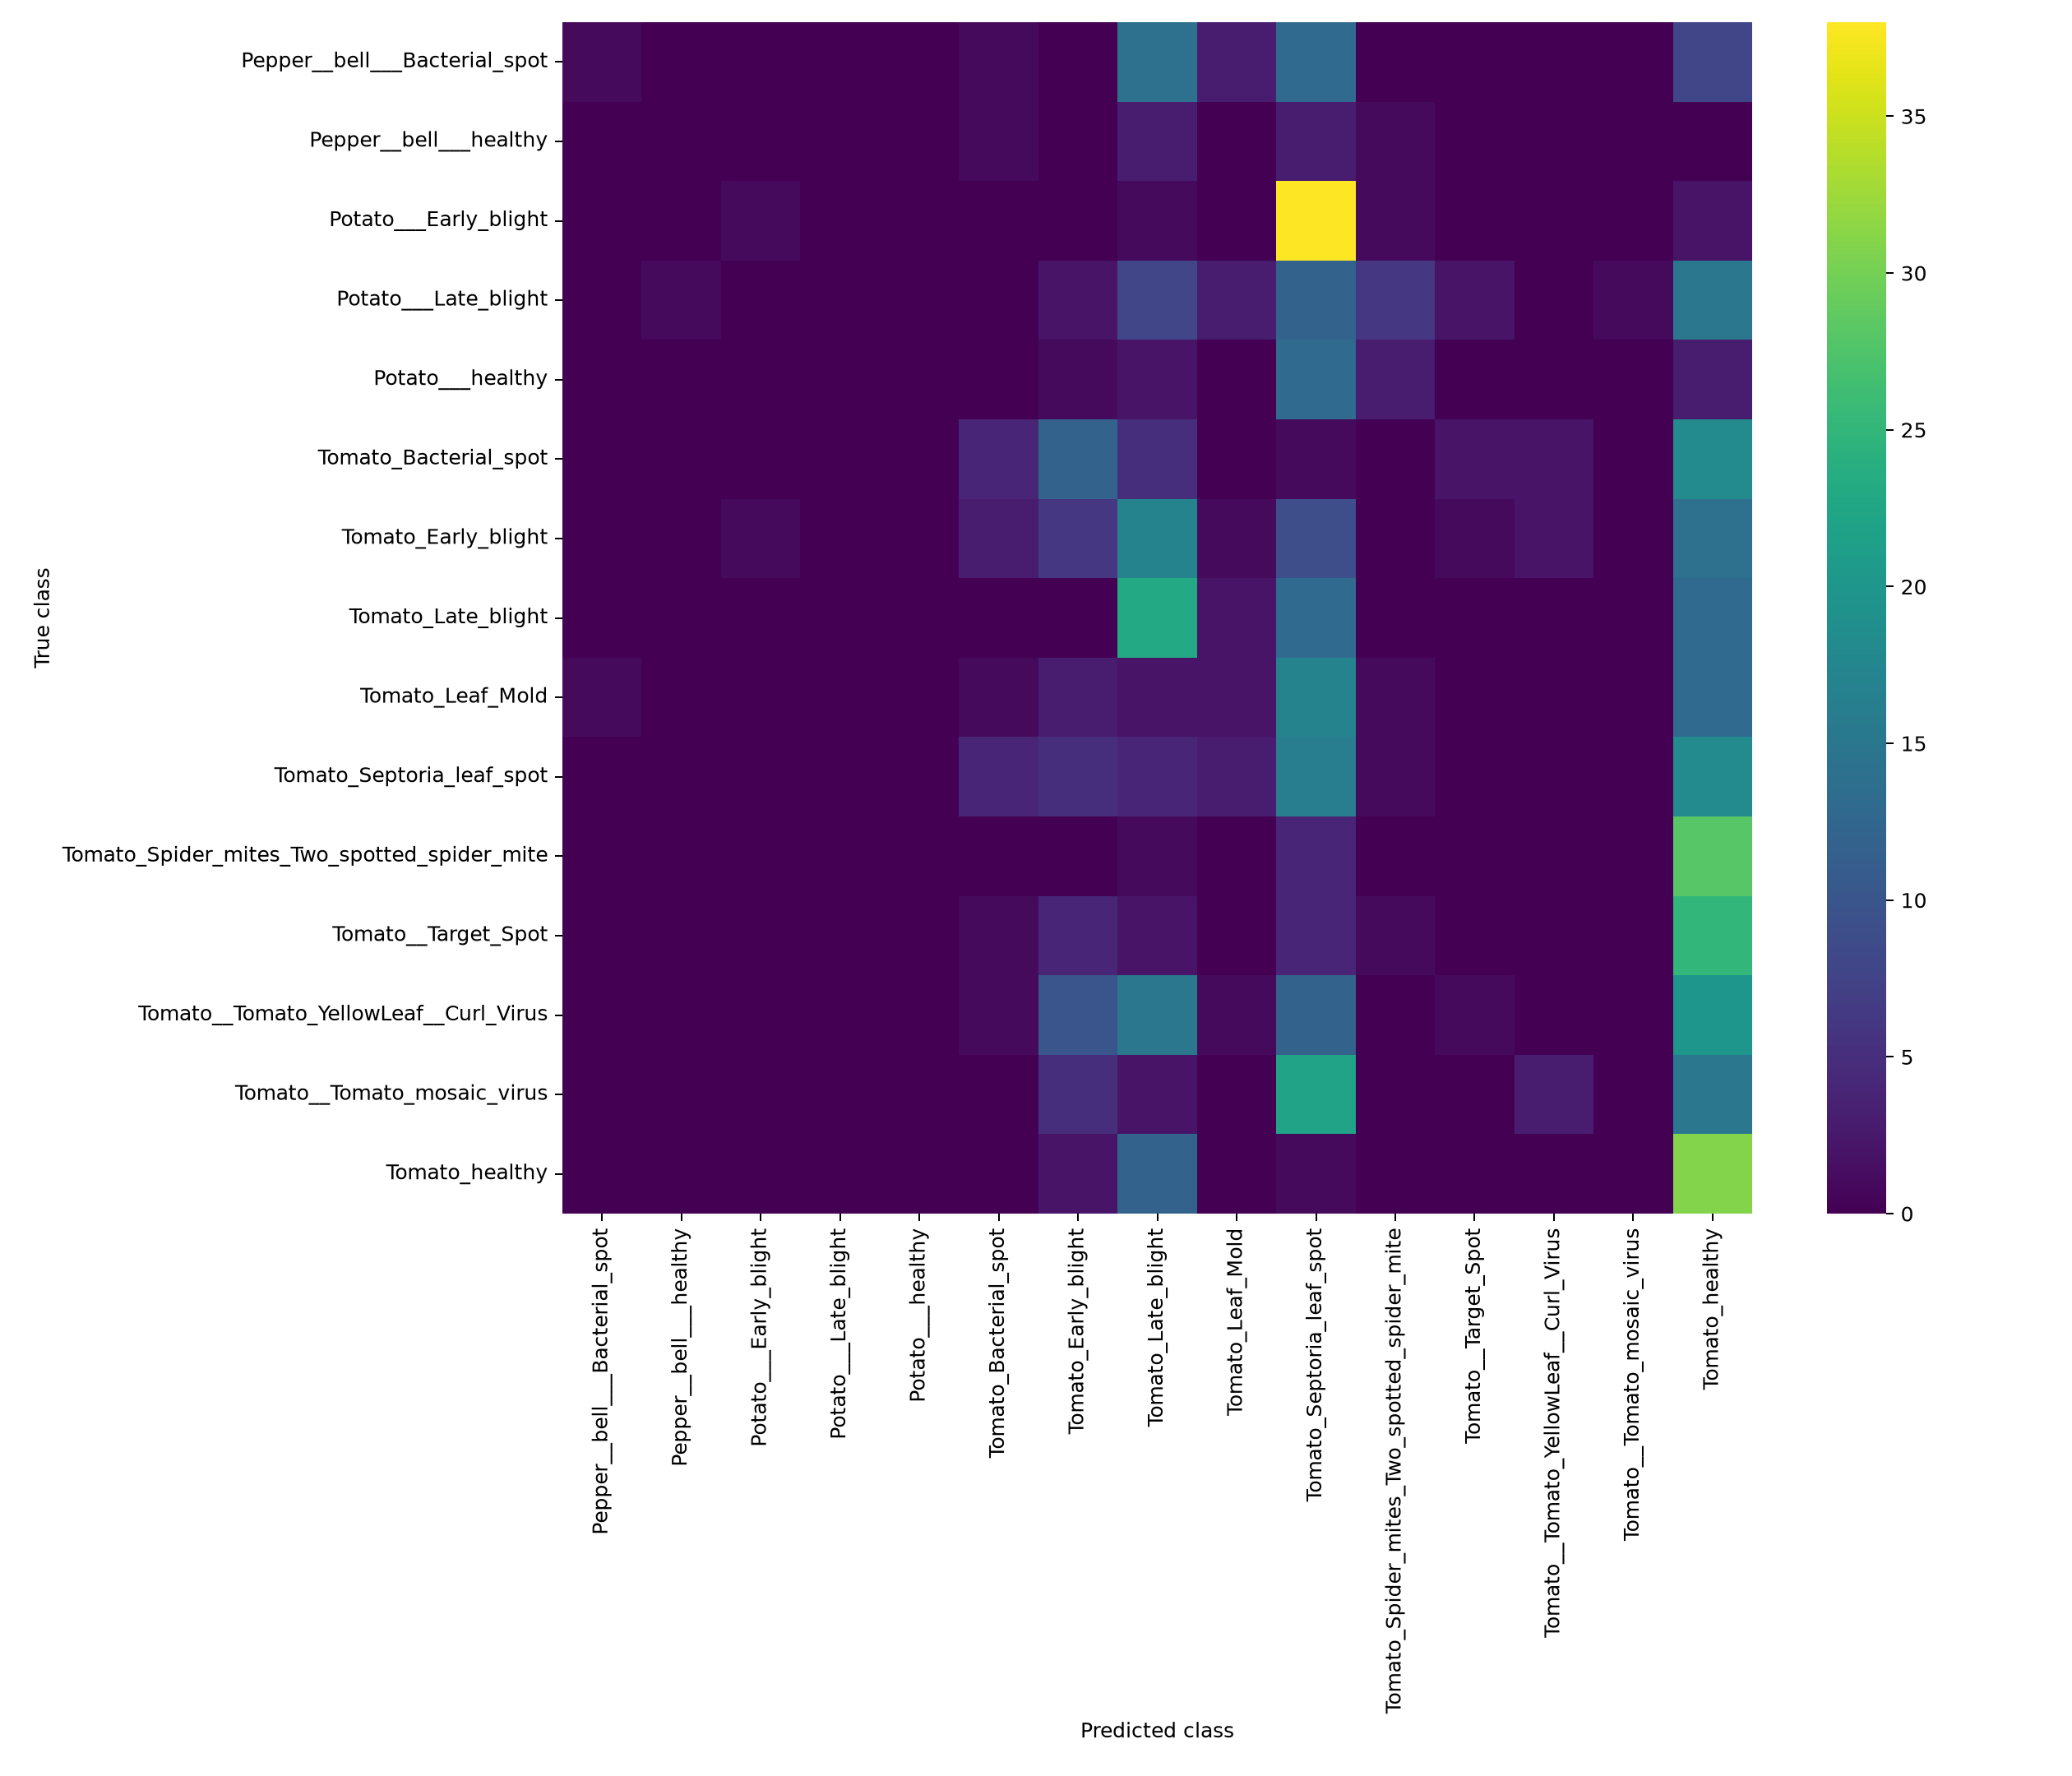

In [1]:
import os
os.environ["TF_ENABLE_ONEDNN_OPTS"] = "0"
os.environ["TF_NUM_INTRAOP_THREADS"] = "1"
os.environ["TF_NUM_INTEROP_THREADS"] = "1"

import importlib.util
import json
from pathlib import Path
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
SCRIPT = ROOT / "scripts" / "train_custom_cnn.py"
spec = importlib.util.spec_from_file_location("custom_cnn_training", SCRIPT)
custom_cnn = importlib.util.module_from_spec(spec)
spec.loader.exec_module(custom_cnn)

# Set True only when intentionally starting a full training run.
RUN_TRAINING = False
if RUN_TRAINING:
    custom_cnn.train_and_evaluate()

meta = custom_cnn.metadata
out = custom_cnn.OUT
print("Dataset image count:", len(meta))
print("Classes:", custom_cnn.num_classes)
print("Split counts:\n", meta["split"].value_counts().reindex(["train", "validation", "test"]))
print("Preprocessing: RGB, resize to 224x224, divide pixel values by 255")
print("Augmentation layers:", [layer.name for layer in custom_cnn.augmentation.layers])
print("Brightness value range:", custom_cnn.augmentation.layers[-1].value_range)
print("Training class weights:")
display(pd.read_csv(custom_cnn.WEIGHTS_PATH))

model = custom_cnn.build_model()
print("Custom CNN model summary:")
model.summary()
print("Training configuration: Adam, learning rate", custom_cnn.LEARNING_RATE,
      "batch size", custom_cnn.BATCH_SIZE, "maximum epochs", custom_cnn.MAX_EPOCHS,
      "sparse categorical crossentropy, early stopping, best-validation checkpoint, and ReduceLROnPlateau")

config_path = out / "experiment_config.json"
history_path = out / "training_history.csv"
if config_path.exists() and history_path.exists():
    config = json.loads(config_path.read_text(encoding="utf-8"))
    history = pd.read_csv(history_path)
    print("Actual training history:")
    display(history)
    print("Actual training analysis:")
    display(config["training_analysis"])
    for filename in ["accuracy_curve.png", "loss_curve.png"]:
        image_path = out / filename
        if image_path.exists():
            display(Image(filename=str(image_path)))
    for filename in ["classification_report.csv", "final_metrics.csv", "model_complexity.csv"]:
        artifact = out / filename
        if artifact.exists():
            print(filename)
            display(pd.read_csv(artifact))
    confusion_path = out / "confusion_matrix.png"
    if confusion_path.exists():
        display(Image(filename=str(confusion_path)))
else:
    print("Training artifacts are not present yet. Run scripts/train_custom_cnn.py after the augmentation check and pipeline benchmark.")
